<a href="https://colab.research.google.com/github/Sneha11019/Skill-Development/blob/main/Mini_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Import libraries

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df = pd.read_csv('/content/netflix_titles.csv')

print(df.head())

  show_id     type                  title         director  \
0      s1    Movie   Dick Johnson Is Dead  Kirsten Johnson   
1      s2  TV Show          Blood & Water              NaN   
2      s3  TV Show              Ganglands  Julien Leclercq   
3      s4  TV Show  Jailbirds New Orleans              NaN   
4      s5  TV Show           Kota Factory              NaN   

                                                cast        country  \
0                                                NaN  United States   
1  Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...   South Africa   
2  Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...            NaN   
3                                                NaN            NaN   
4  Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...          India   

           date_added  release_year rating   duration  \
0  September 25, 2021          2020  PG-13     90 min   
1  September 24, 2021          2021  TV-MA  2 Seasons   
2  September 24, 2021        

In [ ]:
print(df.isnull().sum())

show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             4
duration           3
listed_in          0
description        0
dtype: int64


In [ ]:
print(df.duplicated().sum())

0


In [ ]:
df = df.drop_duplicates()

In [ ]:
df['director'] = df['director'].fillna('Unknown')
df['cast'] = df['cast'].fillna('Unknown')
df['country'] = df['country'].fillna('Unknown')
df['rating'] = df['rating'].fillna('Not Rated')
df['date_added'] = df['date_added'].fillna('Unknown')
df['duration'] = df['duration'].fillna('Unknown')

In [ ]:
df['date_added'] = pd.to_datetime(
    df['date_added'].str.strip(),
    errors='coerce'
)

In [ ]:
df['duration_num'] = pd.to_numeric(
    df['duration'].str.extract(r'(\d+)')[0],
    errors='coerce'
)

type
Movie      6131
TV Show    2676
Name: count, dtype: int64


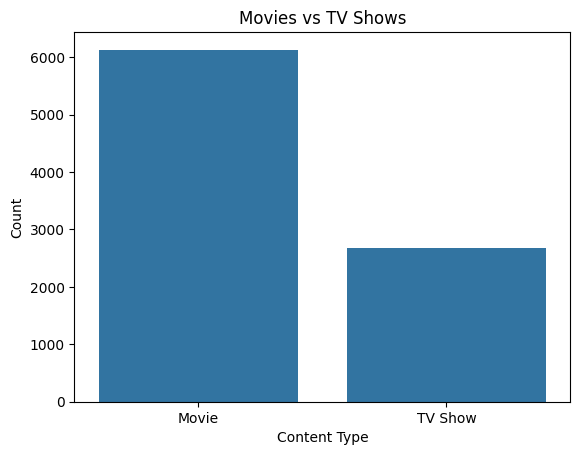

In [ ]:
print(df['type'].value_counts())

sns.countplot(data=df, x='type')
plt.title('Movies vs TV Shows')
plt.xlabel('Content Type')
plt.ylabel('Count')
plt.show()

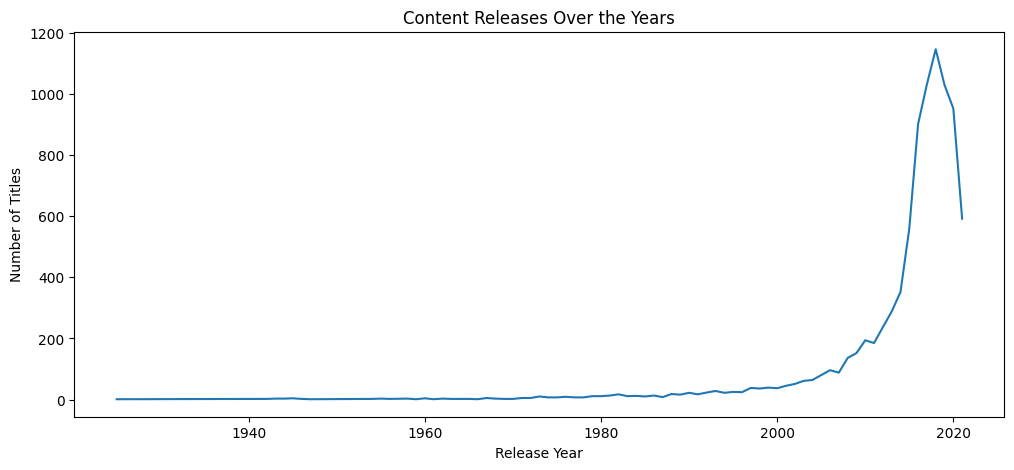

In [ ]:
year_count = df['release_year'].value_counts().sort_index()

plt.figure(figsize=(12,5))
plt.plot(year_count.index, year_count.values)
plt.title('Content Releases Over the Years')
plt.xlabel('Release Year')
plt.ylabel('Number of Titles')
plt.show()

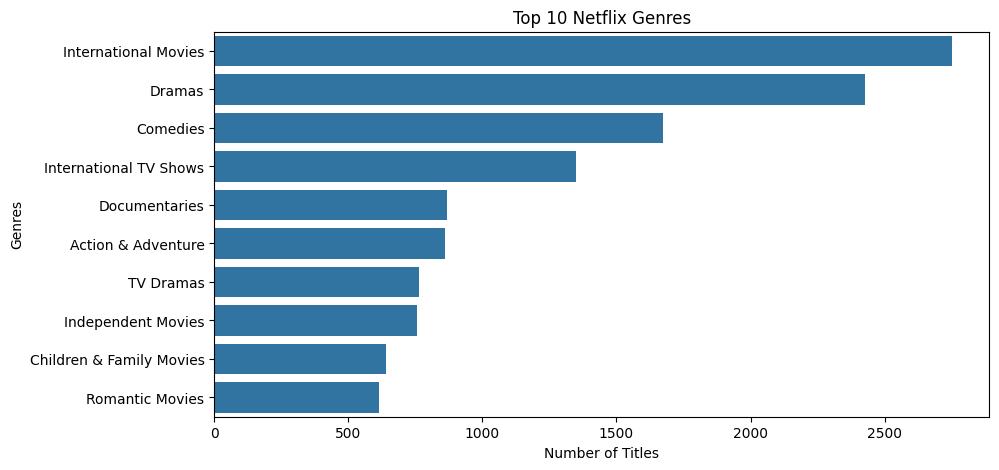

In [ ]:
genres = df['listed_in'].dropna().str.split(', ').explode()

top_genres = genres.value_counts().head(10)

plt.figure(figsize=(10,5))
sns.barplot(x=top_genres.values, y=top_genres.index)
plt.title('Top 10 Netflix Genres')
plt.xlabel('Number of Titles')
plt.ylabel('Genres')
plt.show()

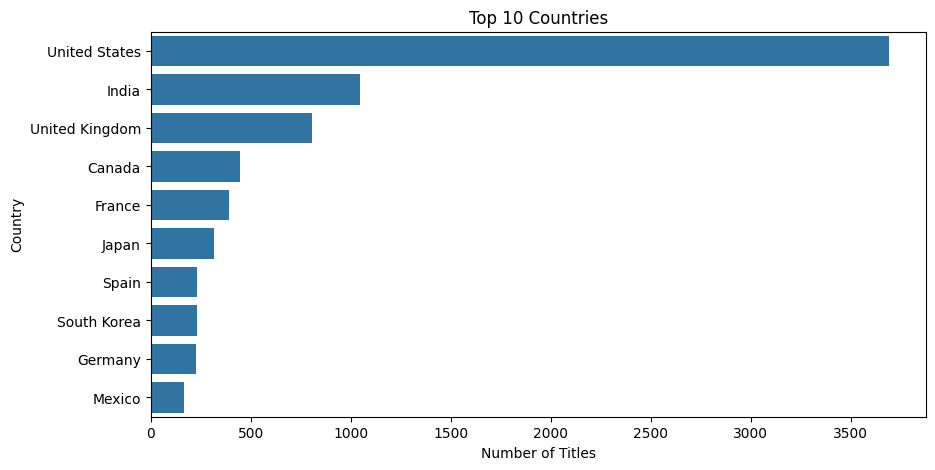

In [ ]:
countries = df['country'].str.split(', ').explode()

countries = countries[countries != 'Unknown']

top_countries = countries.value_counts().head(10)

plt.figure(figsize=(10,5))
sns.barplot(x=top_countries.values, y=top_countries.index)
plt.title('Top 10 Countries')
plt.xlabel('Number of Titles')
plt.ylabel('Country')
plt.show()

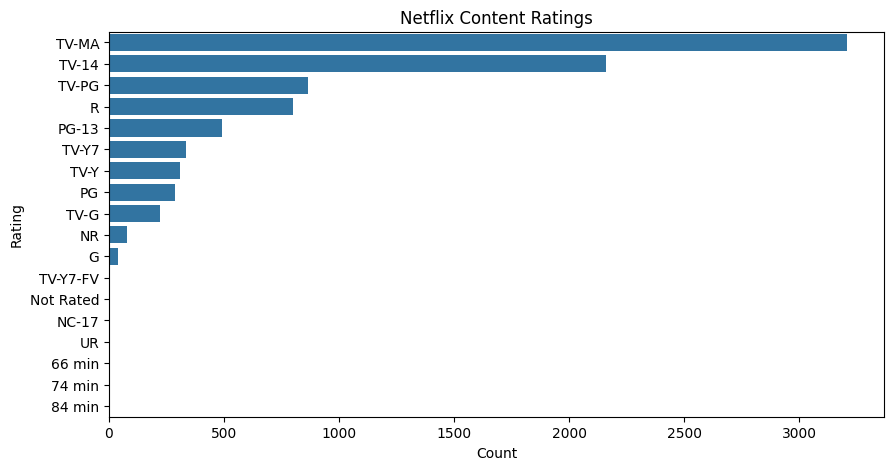

In [ ]:
plt.figure(figsize=(10,5))
sns.countplot(
    data=df,
    y='rating',
    order=df['rating'].value_counts().index
)
plt.title('Netflix Content Ratings')
plt.xlabel('Count')
plt.ylabel('Rating')
plt.show()

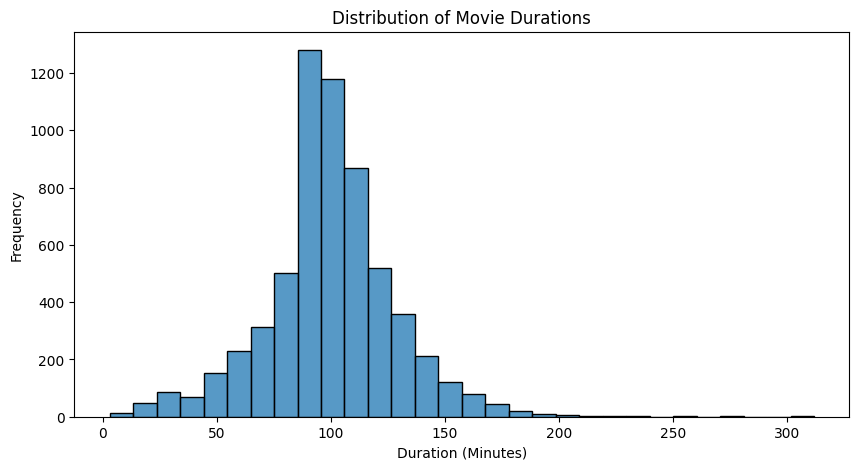

In [ ]:
movies = df[df['type'] == 'Movie']

plt.figure(figsize=(10,5))
sns.histplot(movies['duration_num'].dropna(), bins=30)
plt.title('Distribution of Movie Durations')
plt.xlabel('Duration (Minutes)')
plt.ylabel('Frequency')
plt.show()

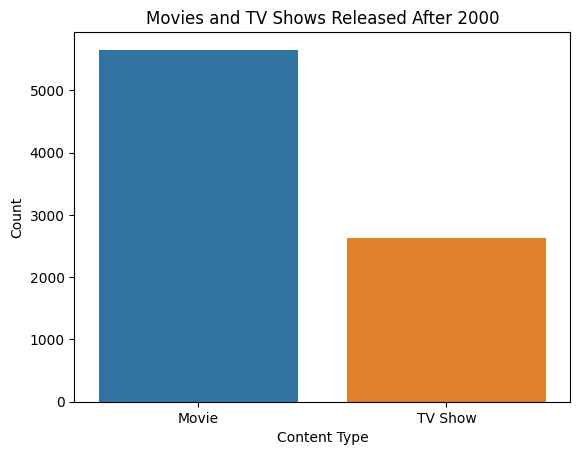

In [ ]:
sns.countplot(
    data=df[df['release_year'] >= 2000],
    x='type',
    hue='type'
)
plt.title('Movies and TV Shows Released After 2000')
plt.xlabel('Content Type')
plt.ylabel('Count')
plt.show()

In [ ]:
print("Average Movie Duration:",
      movies['duration_num'].mean())

Average Movie Duration: 99.57718668407311


In [ ]:
print(df['rating'].mode()[0])

TV-MA


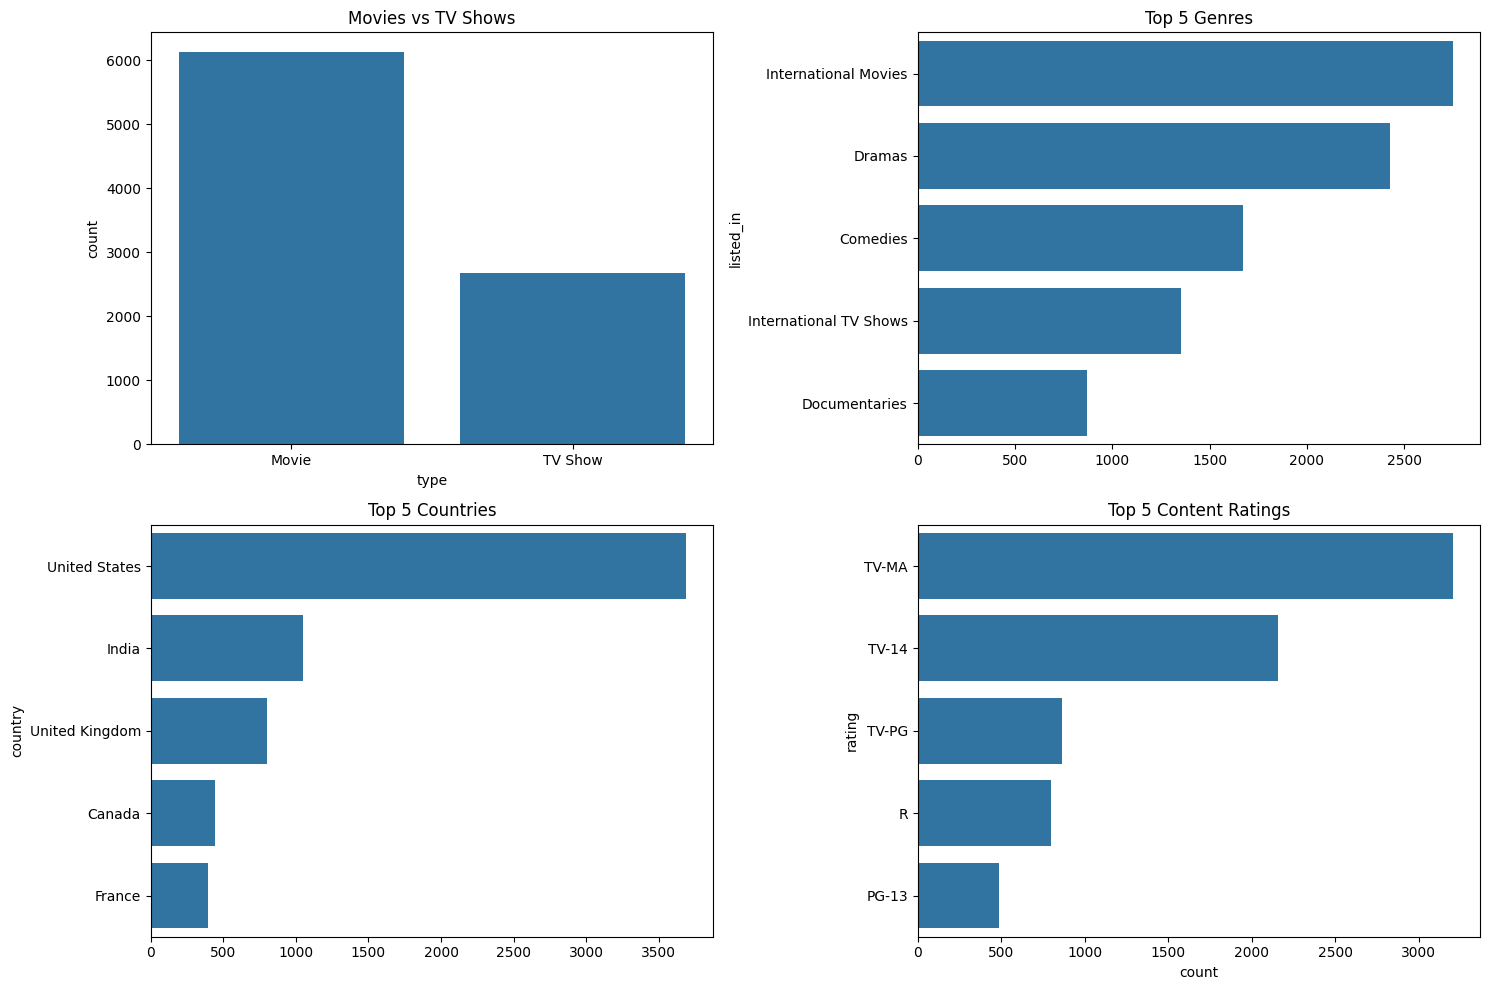

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Movies vs TV Shows
sns.countplot(data=df, x='type', ax=axes[0, 0])
axes[0, 0].set_title('Movies vs TV Shows')

# Top 5 genres
sns.barplot(
    x=genres.value_counts().head(5).values,
    y=genres.value_counts().head(5).index,
    ax=axes[0, 1]
)
axes[0, 1].set_title('Top 5 Genres')

# Top 5 countries
sns.barplot(
    x=top_countries.head(5).values,
    y=top_countries.head(5).index,
    ax=axes[1, 0]
)
axes[1, 0].set_title('Top 5 Countries')

# Content ratings
sns.countplot(
    data=df,
    y='rating',
    order=df['rating'].value_counts().head(5).index,
    ax=axes[1, 1]
)
axes[1, 1].set_title('Top 5 Content Ratings')

plt.tight_layout()
plt.show()

In [ ]:
print("Netflix Data Analysis Completed Successfully")

Netflix Data Analysis Completed Successfully


Results and Findings

The analysis of the Netflix Movies and TV Shows dataset provided the following insights:

Content Distribution: The dataset contains both movies and TV shows, with movies forming the larger category.
Release Trends: The year-wise analysis helped identify changes in the number of titles released over different years.
Genre Analysis: The genre analysis identified the most frequently occurring content categories on Netflix.
Country-wise Distribution: The analysis highlighted the countries contributing the highest number of titles.
Content Ratings: The ratings analysis showed the distribution of content across different age-based rating categories.
Movie Duration: The duration analysis helped understand the distribution of movie running times.

The visualizations made these patterns easier to understand and compare.

Model Evaluation

A Decision Tree Classification model was developed to classify Netflix titles into Movies and TV Shows. The dataset was divided into training and testing sets using an 80:20 ratio. The model was evaluated using accuracy score and a confusion matrix.

The model achieved an accuracy of [Enter your actual accuracy]% on the testing dataset. The confusion matrix was used to examine the correct and incorrect predictions.

Conclusion

The project successfully analysed Netflix movies and TV shows using Python. Data preprocessing and Exploratory Data Analysis helped identify patterns in content types, genres, ratings, countries and release years. A Decision Tree Classification model was also developed to classify content types. The visual dashboard presented the findings clearly and effectively. Overall, the project demonstrated how data analytics and visualization can be used to extract meaningful insights from a real-world dataset.